In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent / "src"))

from results import ModelResults, ModelComparison, build_dataset

In [3]:
dataset = build_dataset()
base_results = ModelResults('024-baseline-1', 'ddpm-1000', epoch=99, dataset_split='test', dataset=dataset)
mp_results = ModelResults('029-mixed-precision', 'ddpm-1000', epoch=99, dataset_split='test', dataset=dataset)

b_results = ModelComparison([base_results, mp_results], ['Baseline', 'Mixed Precision'])

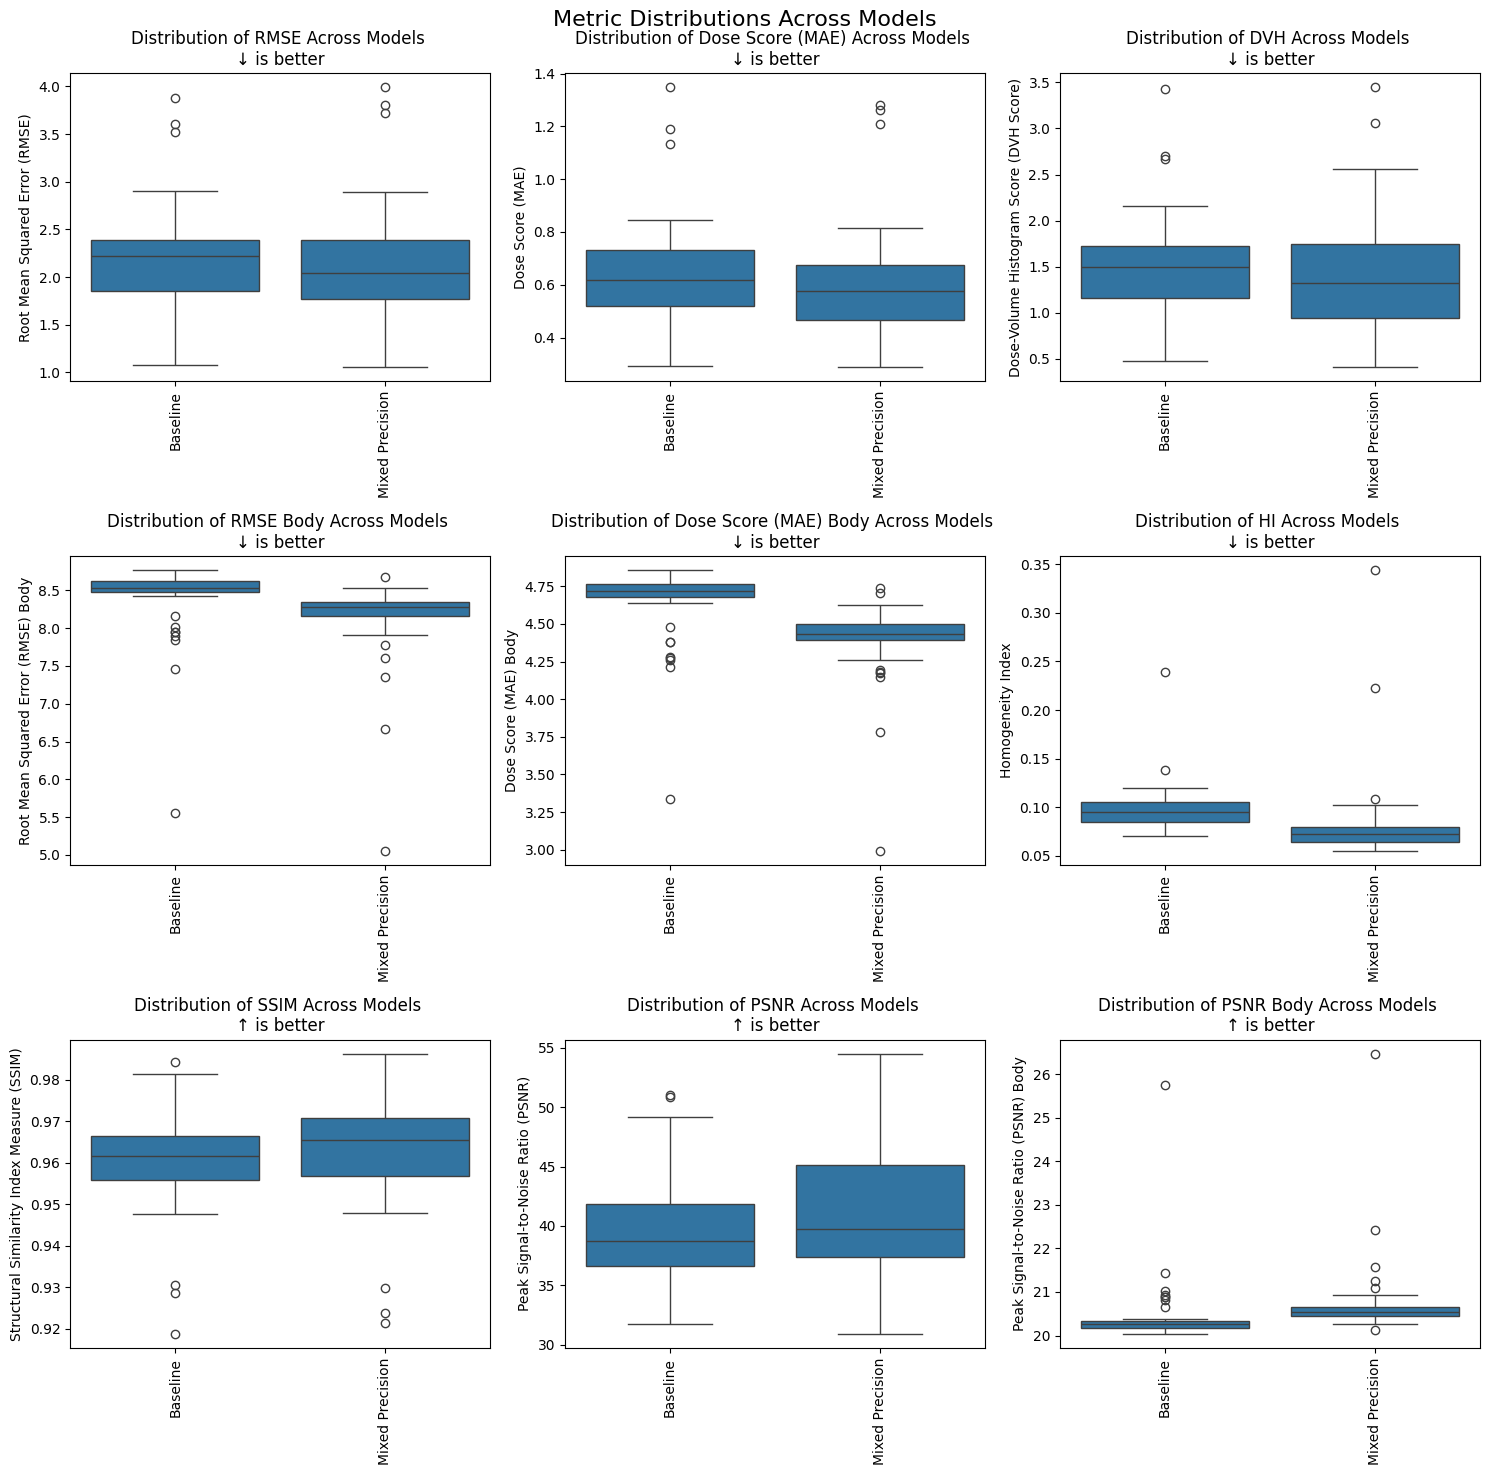

In [4]:
ax = b_results.plot_metric_distributions()

In [6]:
fp16_results = ModelResults('024-baseline-1', 'ddpm-1000-fp16-amp', epoch=99, dataset_split='test', dataset=dataset)
bf16_results = ModelResults('024-baseline-1', 'ddpm-1000-bf16-amp', epoch=99, dataset_split='test', dataset=dataset)
sampling_results = ModelComparison([base_results, fp16_results, bf16_results], ['FP32', 'FP16', 'BF16'])

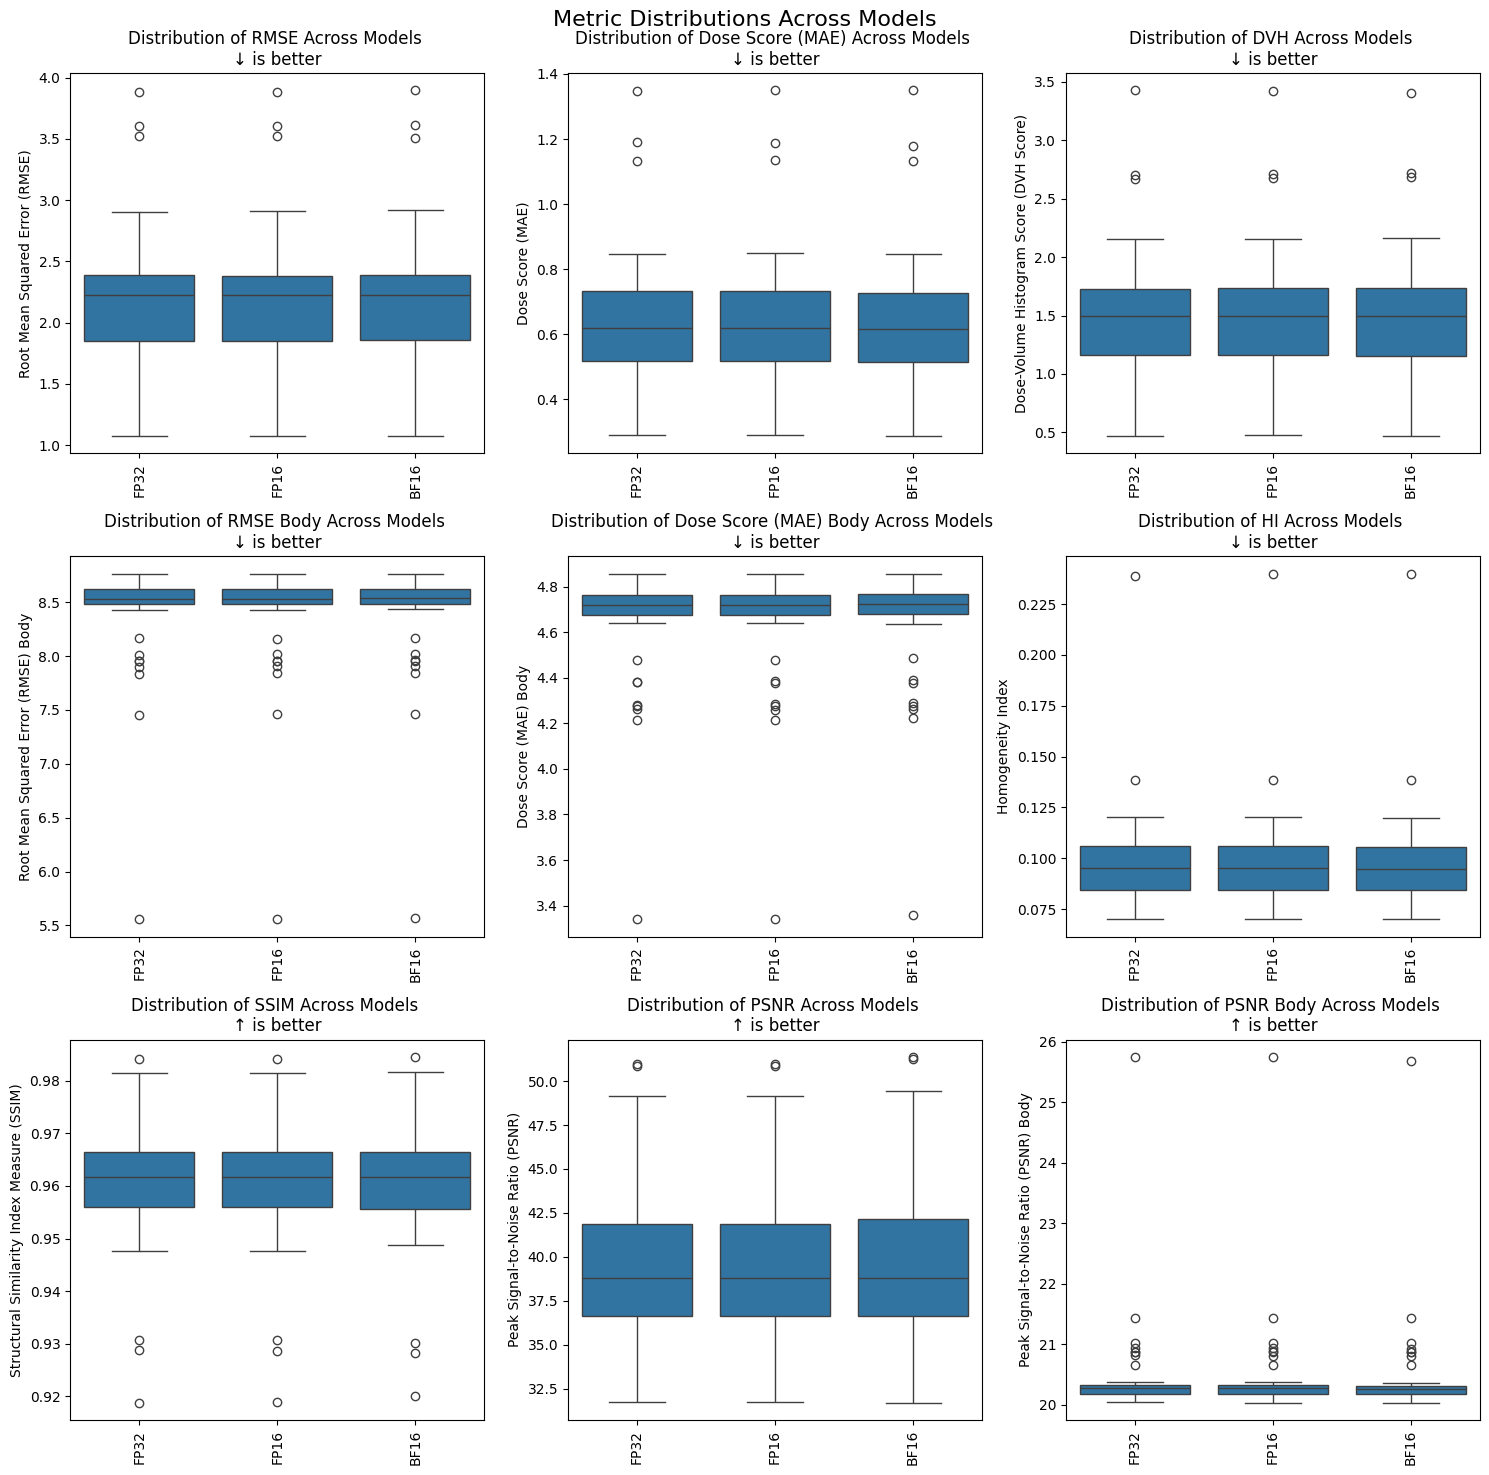

In [7]:
ax = sampling_results.plot_metric_distributions()

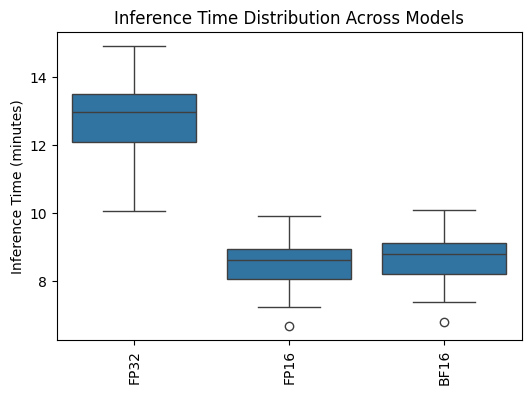

In [8]:
ax = sampling_results.plot_inference_times()

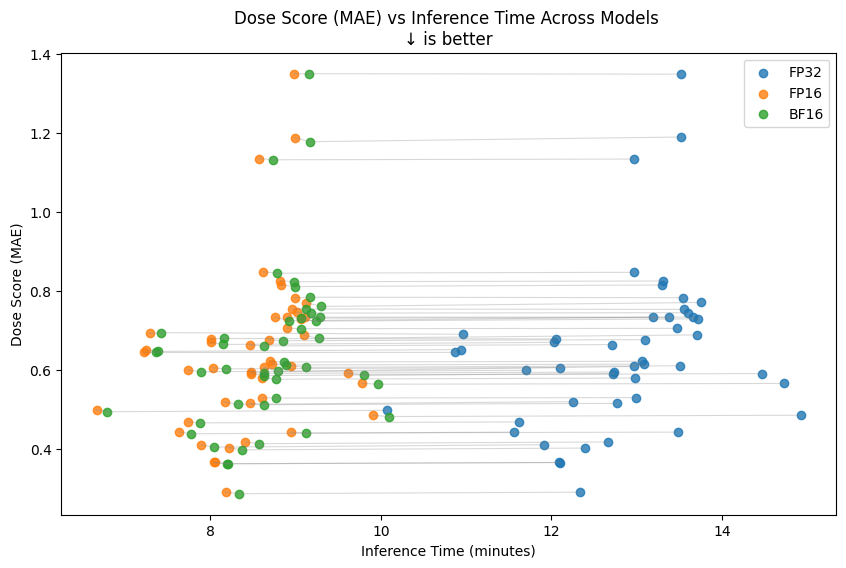

In [20]:
ax = sampling_results.plot_quality_over_time_by_volume('dose_score')